# Lecture: Sprach-Merkmale und Clustering 

In der heutigen Übung betrachten wir Mel Frequency Cepstrum Coefficients, die Standardmerkmale der Sprachverarbeitung. 

Wir führen zuerst ein kMeans-Clustern von Vokalen durch,
anschließend implementieren wir eine Geschlechtserkennung mit kNN.


Sie benoetigen zusaetzlich das Paket soundfile um Audiodateien zu lesen und python_speech_features zur MFCC-Berechnung.


# MFCC berechnung



import matplotlib.pyplot as plt
import numpy as np
import os
import soundfile as sf
import python_speech_features as mfcc
from sklearn.svm import LinearSVC
from sklearn.svm import SVC
import pickle
import operator




In [6]:
import matplotlib.pyplot as plt
import numpy as np
import os
import soundfile as sf
import python_speech_features as mfcc


Folgende Methode berechnet MFCCs auf einer Audiodatei mit Hilfe des Paketes python_speech_features und speichert das Ergebnis 

In [7]:
def extract_feats(audiof):
    """
    extract 20 dim mfcc features from an audio
    """
    
    audio,samplerate= sf.read(audiof);

    mfcc_feat = mfcc.mfcc(audio, samplerate, 0.025, 0.01, 20, appendEnergy=False)

    return mfcc_feat

## KMeans auf Vokalen


- Sprechen Sie die Vokale (a,e,i,o,u) und nehmen sie sich dabei auf.
- Plotten sie die ersten beiden Merkmale der Daten
- Verwenden Sie nun den KMeans um die Daten zu Clustern und erzeugen der Klassenlabels
    - Verwenden Sie dabei zuerst die ersten beiden Merkmale zum fit_predict durch kMeans, und färben  sie den Punkte des Plots mit dem Ergebnisse aus fit_predict ein.
- Verwenden Sie **alle** Merkmale und plotten sie die Ergebnisse erneut.

Wie interpretieren Sie die Ergebnisse?

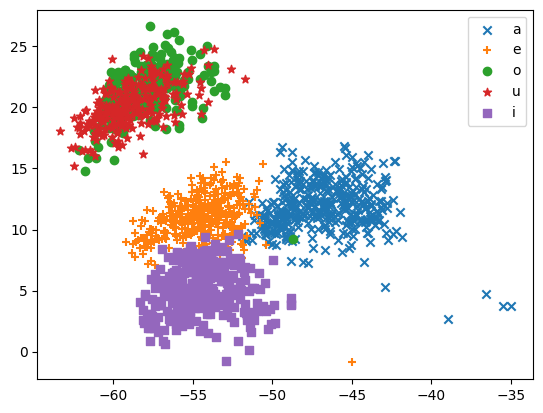

In [8]:
mfccs_a=extract_feats("./data/aaaaa.wav")
mfccs_e=extract_feats("./data/eeeee.wav")
mfccs_i=extract_feats("./data/iiiii.wav")
mfccs_o=extract_feats("./data/ooooo.wav")
mfccs_u=extract_feats("./data/uuuuu.wav")

plt.scatter(mfccs_a[:, 0], mfccs_a[:,1], marker='x', label='a')
plt.scatter(mfccs_e[:, 0], mfccs_e[:,1], marker='+', label='e')
plt.scatter(mfccs_o[:, 0], mfccs_o[:,1], marker='o', label='o')
plt.scatter(mfccs_u[:, 0], mfccs_u[:,1], marker='*', label='u')
plt.scatter(mfccs_i[:, 0], mfccs_i[:,1], marker='s', label='i')
plt.legend(loc="upper right")

data=np.concatenate((mfccs_a,mfccs_e,mfccs_i, mfccs_o,mfccs_u),axis=0)

In [9]:
print(data.shape)

(1575, 20)


/Users/bockletto/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


(1575,)


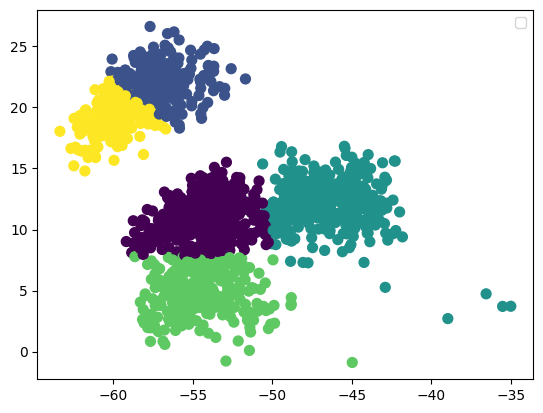

In [10]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=5)

labels_kmeans=kmeans.fit_predict(data[:,[0,1]])
print(labels_kmeans.shape)
plt.scatter(data[:, 0], data[:,1],c=labels_kmeans, s=50, cmap='viridis')
plt.legend(loc="upper right")

/Users/bockletto/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


(1575,)


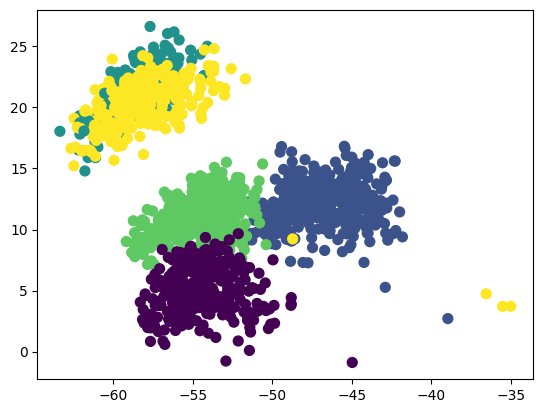

In [11]:
labels_kmeans=kmeans.fit_predict(data)
print(labels_kmeans.shape)
plt.scatter(data[:, 0], data[:,1],c=labels_kmeans, s=50, cmap='viridis')

## AFA-Plot

In [12]:
mfccs_afa=extract_feats("./data/afa.wav")


(398,)


/Users/bockletto/Library/Python/3.9/lib/python/site-packages/sklearn/cluster/_kmeans.py:1416: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


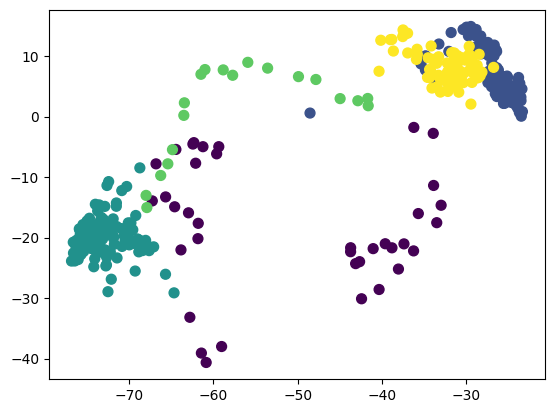

In [13]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=5)

labels_kmeans=kmeans.fit_predict(mfccs_afa)
print(labels_kmeans.shape)
plt.scatter(mfccs_afa[:, 0], mfccs_afa[:,1],c=labels_kmeans, s=50, cmap='viridis')